<a href="https://colab.research.google.com/github/RayaRabbani129/PCVK_Ganjil_2026/blob/main/Week07_23.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Tugas Praktikum**

# **Tugas Mandiri**

In [16]:
NAMA  = 'RAYA RABBANI A'
NIM   = '244107020159'

print(NAMA)
print(NIM)

RAYA RABBANI A
244107020159


In [17]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

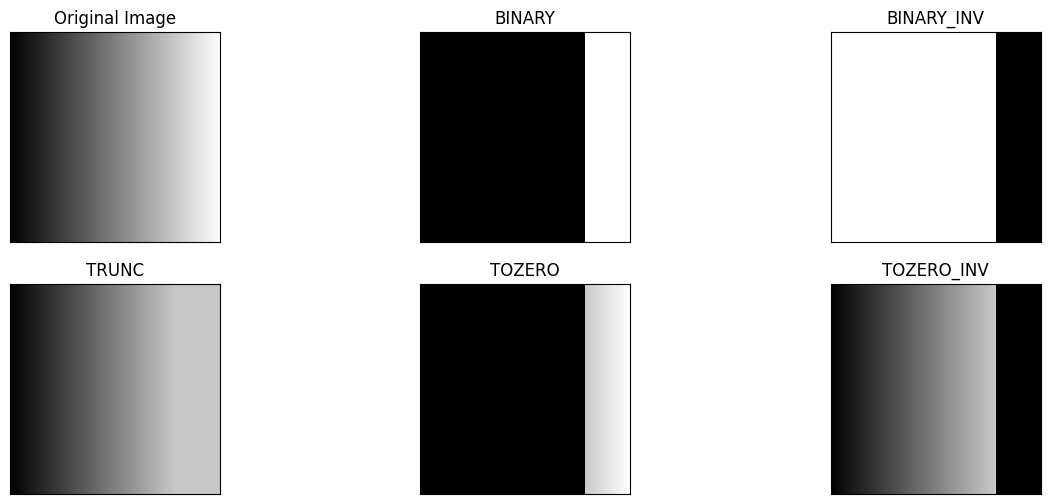

In [19]:
import os
import numpy as np
import matplotlib.pyplot as plt

def th_binary(img, thresh, maxval=255):
    return np.where(img > thresh, maxval, 0).astype(np.uint8)

def th_binary_inv(img, thresh, maxval=255):
    return np.where(img > thresh, 0, maxval).astype(np.uint8)

def th_trunc(img, thresh):
    return np.where(img > thresh, thresh, img).astype(np.uint8)

def th_tozero(img, thresh):
    return np.where(img > thresh, img, 0).astype(np.uint8)

def th_tozero_inv(img, thresh):
    return np.where(img > thresh, 0, img).astype(np.uint8)

# Pembuatan citra gradien horizontal dari hitam (0) ke putih (255)
img_grad = np.tile(np.arange(256, dtype=np.uint8), (256, 1))

# --- citra gradien
thresh, maxval = 200, 255
hasil = [img_grad,
         th_binary(img_grad, thresh, maxval),
         th_binary_inv(img_grad, thresh, maxval),
         th_trunc(img_grad, thresh),
         th_tozero(img_grad, thresh),
         th_tozero_inv(img_grad, thresh)]
titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']

plt.figure(figsize=(15, 6))
for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(hasil[i], 'gray', vmin=0, vmax=255, interpolation='nearest')  # vmin/vmax agar TRUNC tampil abu-abu, bukan di-stretch
    plt.title(titles[i]); plt.xticks([]); plt.yticks([])
plt.show()

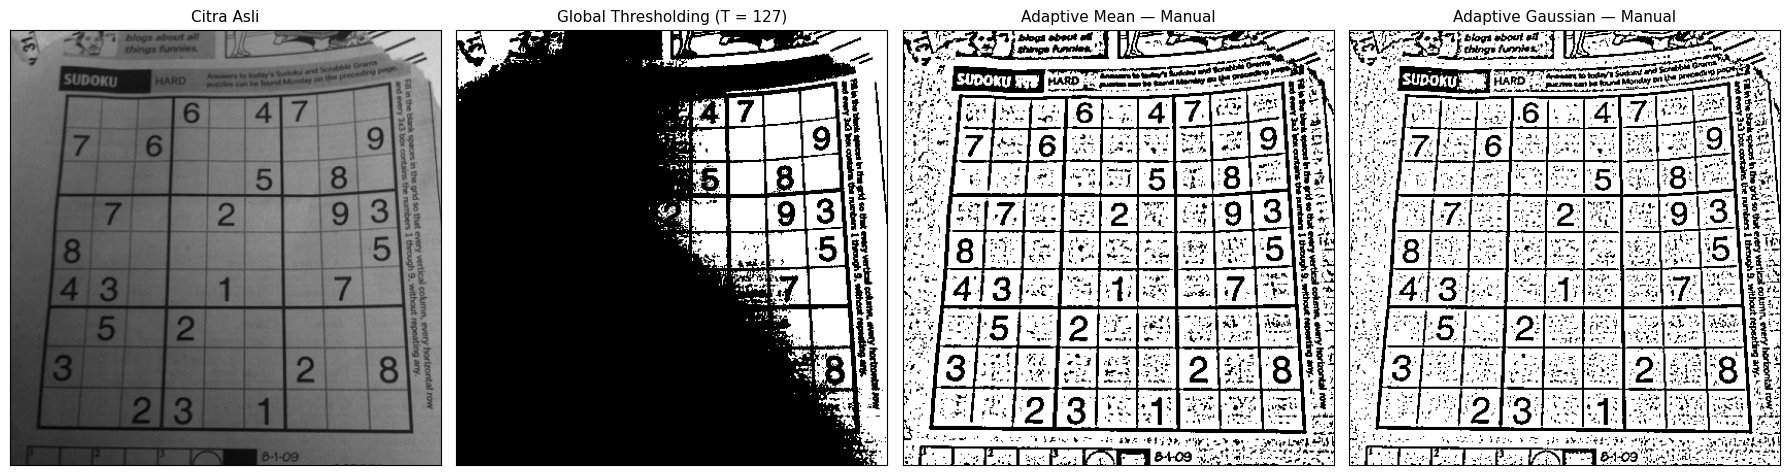

In [20]:
filename = '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/sudoku-original.jpg'
img_bgr = cv.imread(filename)
gray = np.dot(img_bgr[..., :3], [0.114, 0.587, 0.299]).astype(np.uint8)

thresh_val = 127
th1 = np.where(gray > thresh_val, 255, 0).astype(np.uint8)

block_size = 11
C = 2
sigma = 2
pad = block_size // 2
padded_gray = np.pad(gray, pad, mode='reflect')

x, y = np.meshgrid(np.arange(-pad, pad + 1), np.arange(-pad, pad + 1))
gaussian_kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))
gaussian_kernel /= gaussian_kernel.sum()

height, width = gray.shape
th2 = np.zeros((height, width), dtype=np.uint8)
th3 = np.zeros((height, width), dtype=np.uint8)

for i in range(height):
    for j in range(width):
        window = padded_gray[i:i + block_size, j:j + block_size]
        mean_val = np.mean(window)
        T_mean = mean_val - C
        th2[i, j] = 255 if gray[i, j] > T_mean else 0
        gauss_val = np.sum(window * gaussian_kernel)
        T_gauss = gauss_val - C
        th3[i, j] = 255 if gray[i, j] > T_gauss else 0

titles = [
    'Citra Asli',
    'Global Thresholding (T = 127)',
    'Adaptive Mean — Manual',
    'Adaptive Gaussian — Manual'
]
citra2 = [gray, th1, th2, th3]

plt.figure(figsize=(18, 5))
for i in range(len(citra2)):
    plt.subplot(1, 4, i + 1)
    plt.imshow(citra2[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i], fontsize=11)
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()

/tmp/ipykernel_2850/3441874691.py:20: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)


114


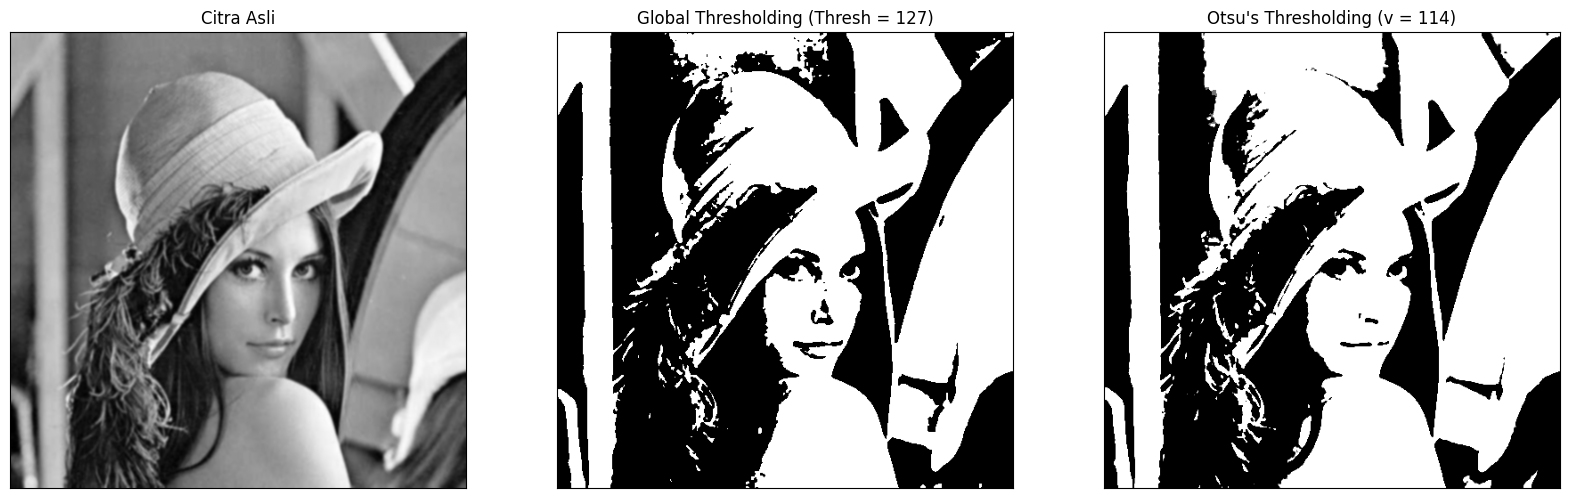

In [21]:
filename = ('/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/lena.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) +
')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

/tmp/ipykernel_2850/2519745977.py:19: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)


166


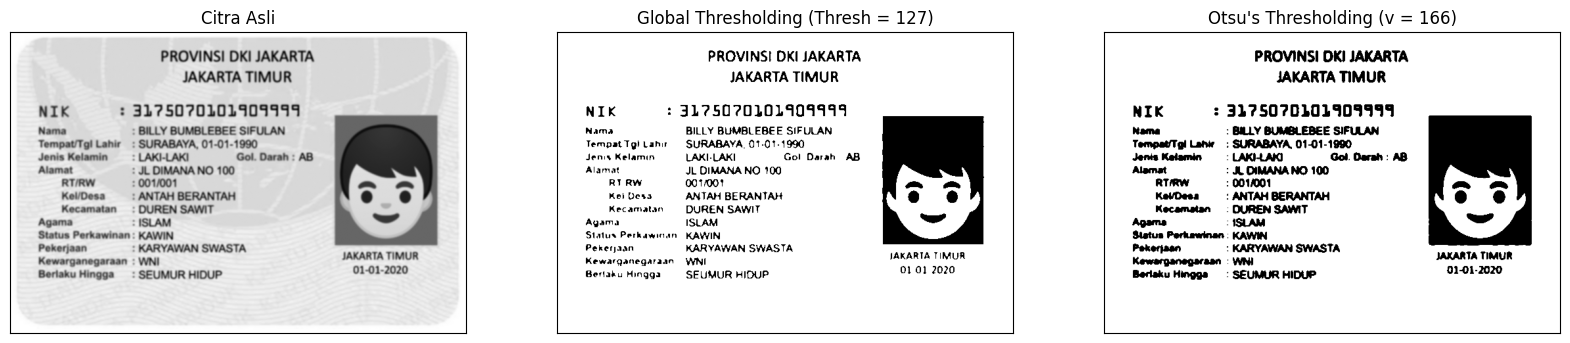

In [22]:
filename = ('/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/ktp_fulan.jpg')
img = cv.imread(filename,0)
blur = cv.GaussianBlur(img,(5,5),0)
thresh=127

def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v = ")+str(otsu_thresh)+")"
ret,th1 = cv.threshold(blur,thresh,255,cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh = ' + str(thresh) +
')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize = (20,15))
for i in range(len(citra3)):
    plt.subplot(1,3,i+1),plt.imshow(citra3[i],'gray')
    plt.title(titles[i])
    plt.xticks([]),plt.yticks([])
plt.show()

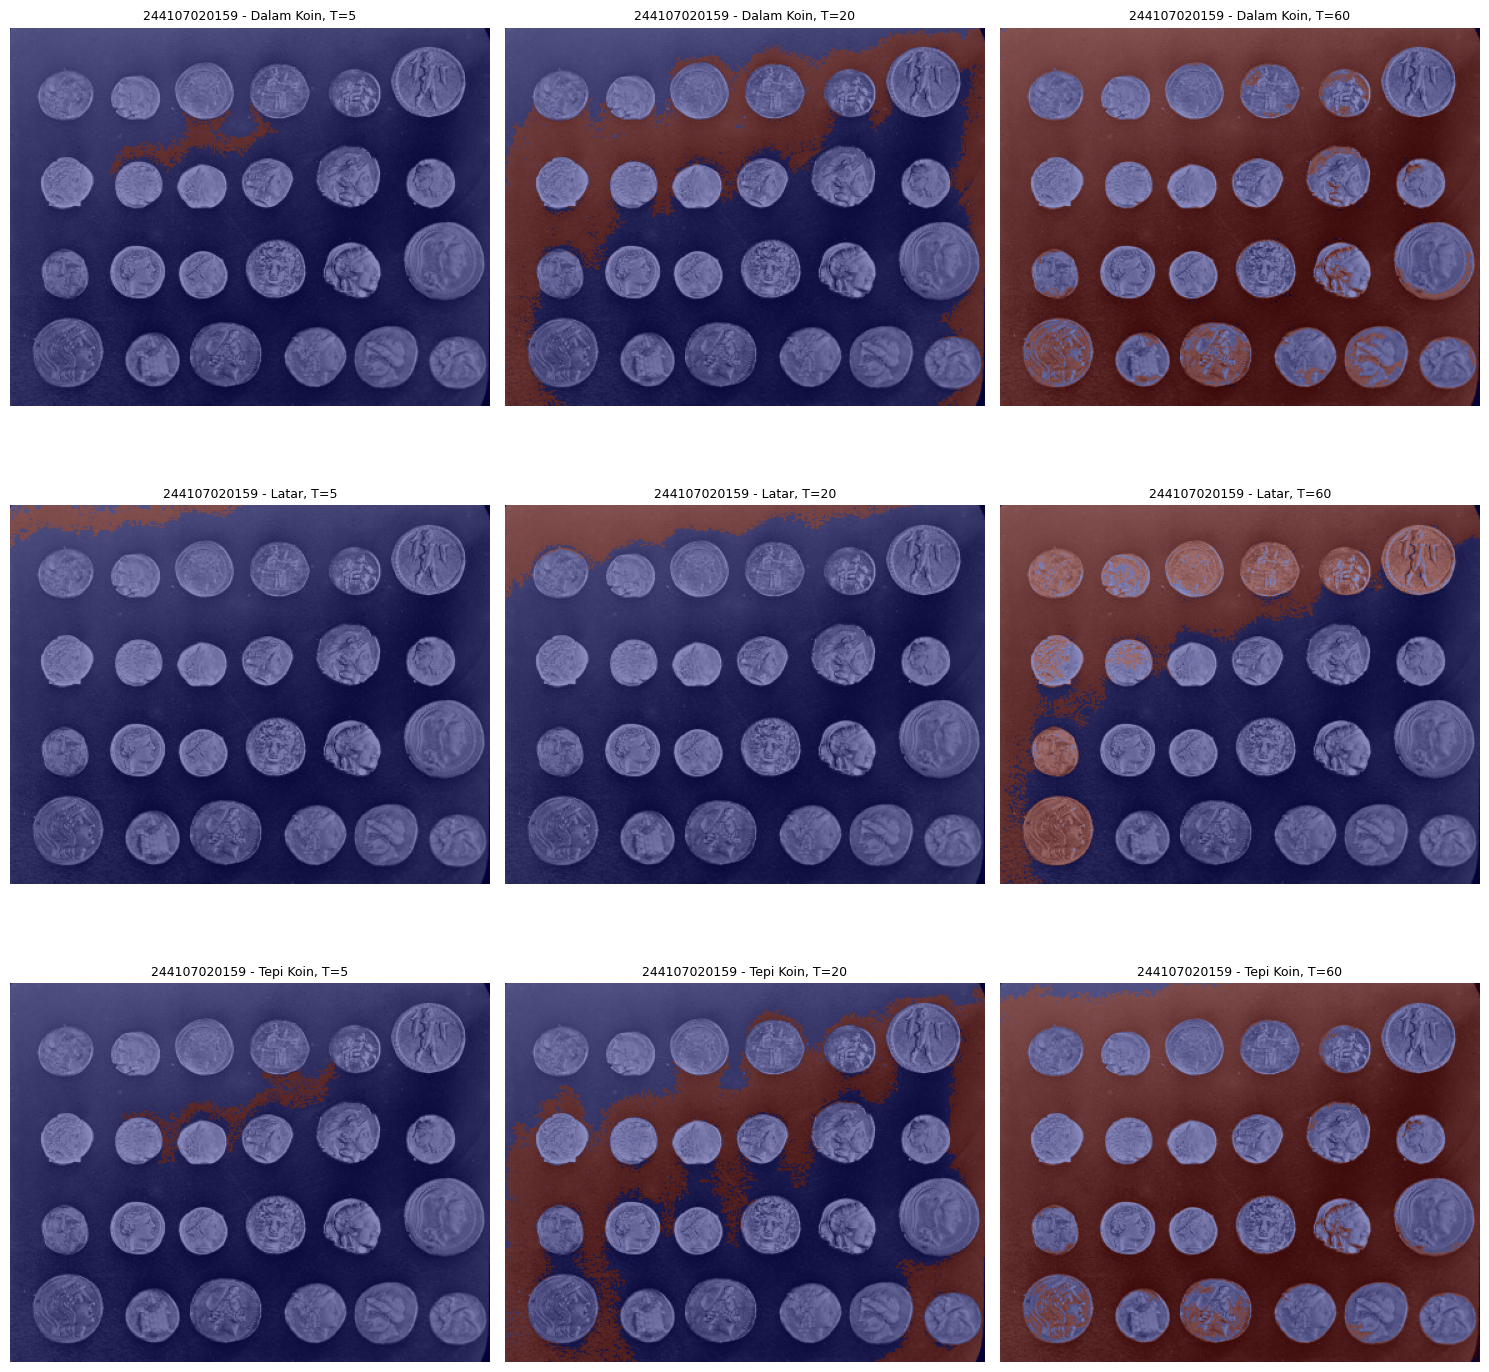

In [23]:
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

coins = data.coins()

# 3 seed: dalam koin, latar, tepi koin
seeds = {'Dalam Koin': (100, 100), 'Latar': (10, 10), 'Tepi Koin': (100, 150)}
T_values = [5, 20, 60]

plt.figure(figsize=(15,15))
idx = 1
for seed_name, seed_point in seeds.items():
    for T in T_values:
        mask = flood(coins, seed_point, tolerance=T)
        plt.subplot(3, 3, idx)
        plt.imshow(coins, cmap='gray')
        plt.imshow(mask, cmap='jet', alpha=0.4)
        plt.title(NIM + f' - {seed_name}, T={T}', fontsize=9)
        plt.axis('off')
        idx += 1
plt.tight_layout()
plt.show()

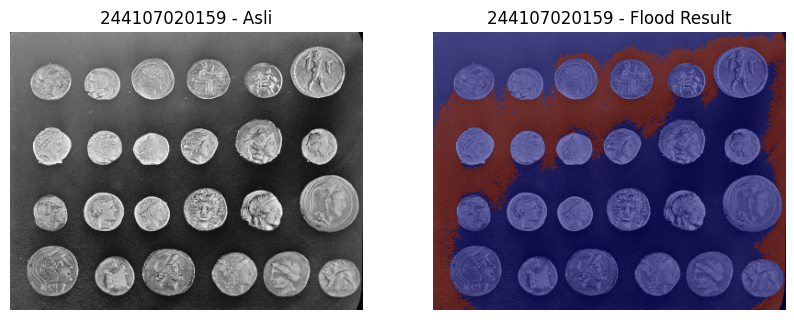

In [24]:
from skimage.segmentation import flood

seed_point = (100, 100)
mask_flood = flood(coins, seed_point, tolerance=20)

plt.figure(figsize=(10,5))
plt.subplot(1,2,1); plt.imshow(coins, cmap='gray'); plt.title(NIM + ' - Asli'); plt.axis('off')
plt.subplot(1,2,2); plt.imshow(coins, cmap='gray'); plt.imshow(mask_flood, cmap='jet', alpha=0.5)
plt.title(NIM + ' - Flood Result'); plt.axis('off')
plt.show()

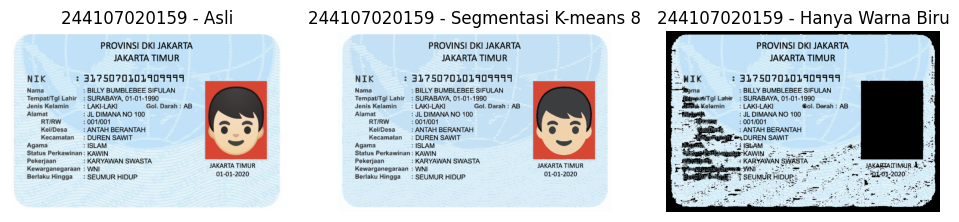

In [25]:
import cv2
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

ktp = cv.imread('/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/ktp_fulan.jpg')
hsv = cv.cvtColor(ktp, cv.COLOR_BGR2HSV)
H, S, V = cv.split(hsv)

kelompok_biru = np.where((H >= 85) & (H <= 130) & (S >= 25) & (V >= 40))

mask_biru = np.zeros(H.shape, dtype=np.uint8)
mask_biru[kelompok_biru] = 255
#k means
filename = ('/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/ktp_fulan.jpg')
img = cv.imread(filename)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
# Ubah citra menjadi array 2D (piksel)
Z = img.reshape((-1, 3))
Z = np.float32(Z)
# Tentukan jumlah cluster
k = 8
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(Z)
# Dapatkan label dan pusat cluster
labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)
# Bentuk citra hasil segmentasi
segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img.shape)

hasil_biru = cv.bitwise_and(ktp, ktp, mask=mask_biru)

plt.figure(figsize=(12,5))
plt.subplot(1,3,1); plt.imshow(cv.cvtColor(ktp, cv.COLOR_BGR2RGB)); plt.title(NIM + ' - Asli'); plt.axis('off')
plt.subplot(1,3,2); plt.imshow(segmented_img); plt.title(NIM + ' - Segmentasi K-means 8'); plt.axis('off')
plt.subplot(1,3,3); plt.imshow(cv.cvtColor(hasil_biru, cv.COLOR_BGR2RGB)); plt.title(NIM + ' - Hanya Warna Biru'); plt.axis('off')
plt.show()

# Kerja Kelompok
Instruksi pengerjaan:
1. Siapkan tiga citra untuk dibandingkan:
- Citra berwarna asli.
- Citra hasil segmentasi menggunakan Otsu Thresholding.
- Citra hasil segmentasi menggunakan Adaptive Thresholding.
Gunakan ukuran citra yang sama. Untuk kedua metode thresholding, ubah citra menjadi
grayscale terlebih dahulu.
2. Lakukan pembacaan teks pada ketiga citra menggunakan pytesseract.image_to_string().
Gunakan bahasa dan pengaturan --psm yang sama agar perbandingan konsisten.
3. Tampilkan area teks yang dikenali menggunakan pytesseract.image_to_data() dan kotak
hijau. Gunakan batas confidence yang sama, misalnya lebih dari 60, pada ketiga citra.
4. Bandingkan hasil pembacaan dengan tulisan sebenarnya pada gambar. Pilih 10 kata atau
angka yang terlihat jelas sebagai acuan, lalu isi tabel berikut. Penilaian dilakukan pada teks
hasil OCR, bukan hanya pada kata yang diberi kotak.
5. Hitung persentase kecocokan untuk setiap metode. Hasil dinyatakan cocok jika seluruh huruf
atau angka pada item sama dengan acuan; abaikan perbedaan huruf besar dan kecil serta
spasi di awal/akhir.
Item yang tidak terbaca dihitung sebagai tidak cocok. Lengkapi ringkasan berikut:

In [26]:
!apt-get install -y tesseract-ocr tesseract-ocr-ind > /dev/null
!pip install pytesseract > /dev/null

In [27]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

PATH = '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/KELOMPOK/'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


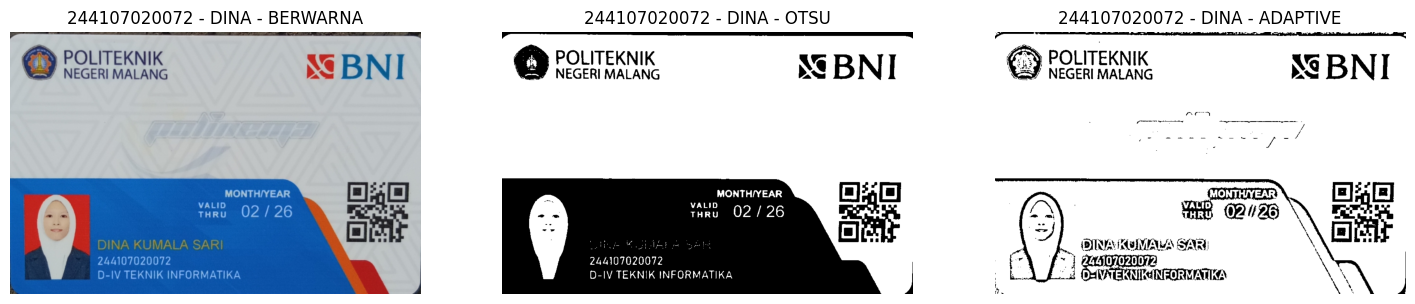

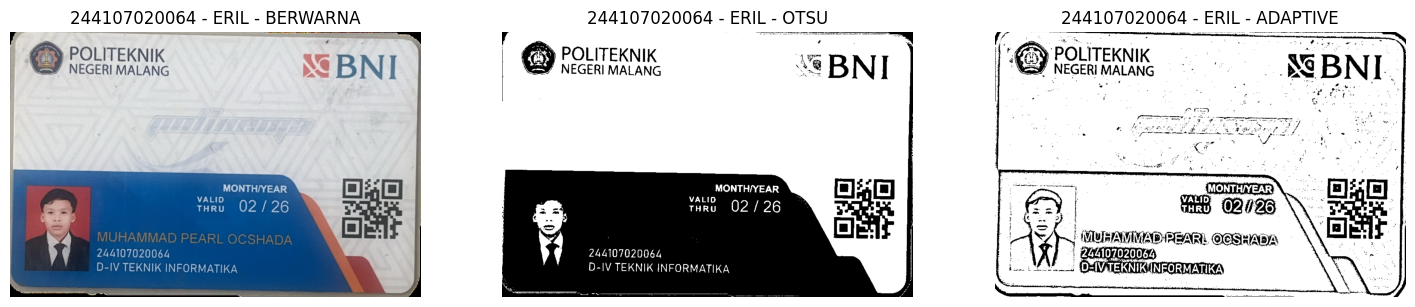

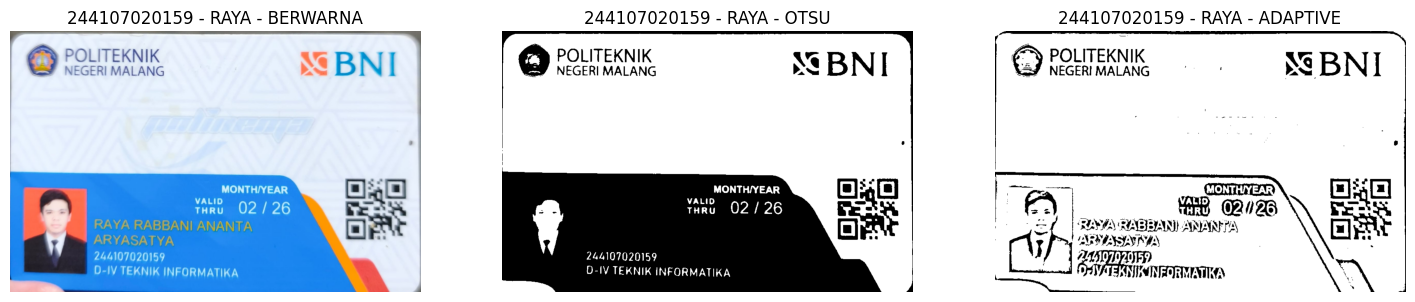

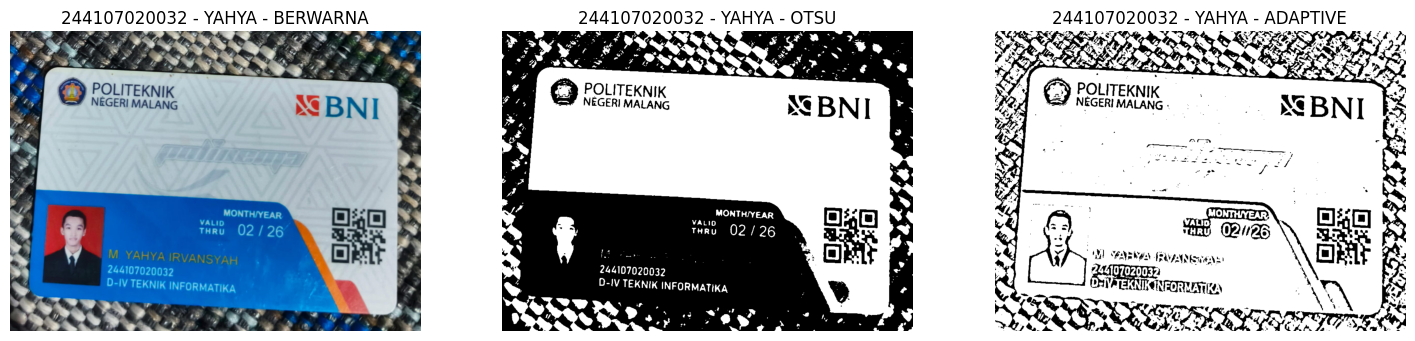

In [32]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
import os
from google.colab import drive
drive.mount('/content/drive')

NAMA = 'RAYA RABBANI ANANTA A'
NIM = '244107020072'

BASE = '/content/drive/MyDrive/Kuliah/SEMESTER 5/PCVK/KELOMPOK'

# Menyesuaikan dengan nama file asli di Google Drive Anda
anggota = [
    '244107020072 - DINA',
    '244107020064 - ERIL',
    '244107020159 - RAYA',
    '244107020032 - YAHYA'
]

LEBAR = 1000
CONFIG = '--psm 3'
LANG = 'ind'
CONF_MIN = 78

def siapkan(nama):
    # Daftar ekstensi yang akan dicoba jika .jpg tidak ditemukan
    possible_extensions = ['.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG']
    bgr = None
    img_path = ""

    for ext in possible_extensions:
        # Mencari berdasarkan nama file persis (tanpa awalan KTM_)
        temp_path = f"{BASE}/{nama}{ext}"
        if os.path.exists(temp_path):
            img_path = temp_path
            bgr = cv.imread(img_path)
            if bgr is not None:
                break

    if bgr is None:
        raise FileNotFoundError(f"Gambar untuk '{nama}' tidak ditemukan di {BASE}/ dengan ekstensi apa pun. Silakan periksa nama file Anda di Google Drive.")

    h, w = bgr.shape[:2]
    bgr = cv.resize(bgr, (LEBAR, int(h * LEBAR / w)))
    gray = cv.cvtColor(bgr, cv.COLOR_BGR2GRAY)
    _, otsu = cv.threshold(gray, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    adaptive = cv.adaptiveThreshold(gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                    cv.THRESH_BINARY, 31, 10)
    return {'BERWARNA': bgr, 'OTSU': otsu, 'ADAPTIVE': adaptive}

try:
    data = {n: siapkan(n) for n in anggota}

    # Tampilkan tiga citra untuk dibandingkan
    for n in anggota:
        plt.figure(figsize=(18,5))
        for i, (k, c) in enumerate(data[n].items(), 1):
            plt.subplot(1,3,i)
            plt.imshow(cv.cvtColor(c, cv.COLOR_BGR2RGB) if c.ndim == 3 else c, cmap='gray')
            plt.title(n + ' - ' + k)
            plt.axis('off')
        plt.show()
except FileNotFoundError as e:
    print("Error:", e)

In [33]:
hasil_teks = {}
for n in anggota:
    print('#' * 20, n.upper(), '#' * 20)
    hasil_teks[n] = {}
    for k, c in data[n].items():
        teks = pytesseract.image_to_string(c, lang=LANG, config=CONFIG)
        hasil_teks[n][k] = teks
        print('=' * 10, k, '=' * 10)
        print(teks.strip())
        print()

#################### 244107020072 - DINA ####################
========== BERWARNA ==========
€3 POLITEKNIK
NE NEGERI MALANG

Oo
,

N/
TA

========== OTSU ==========
P
NEGERI MALANG Ac BNI

MONTH/YEAR

Tiru 02/26

244107020072
D-IV TEKNIK INFORMATIKA

========== ADAPTIVE ==========
(9P | —
& 9 PO TEKNIK, BNI

MOINAIKUMALAISARI
WN R22 2707020072
ME D-IVATEKNIKSINEORMATIKAS

#################### 244107020064 - ERIL ####################
========== BERWARNA ==========
DO POLITEKNIK
£- NEGERI MALANG

MONTH/YEAR

tnRu 02/26

MUHAMMAD PEARI
244107020064
D-IV TEKNIK INFORMATIKA

TN Ni Nb BE MENED SLS

========== OTSU ==========
#
| POLITEKNIK
EP NEGERI MALANG

MONTH/YEAR

& TnRo 02/26
X| 244107020064

D-IV TEKNIK INFORMATIKA

========== ADAPTIVE ==========
1
D POLITEKNIK
NEGERI MALANG

IMONTH/YEAR)
| TB Mia
3 MAH ANAD FAR. O @ESHAIA

#################### 244107020159 - RAYA ####################
========== BERWARNA ==========
@ POLITEKNIK
NEGERI MALANG

ya
Pss

RAYA RAS SAN ANANTA
ARYASANNYA

==

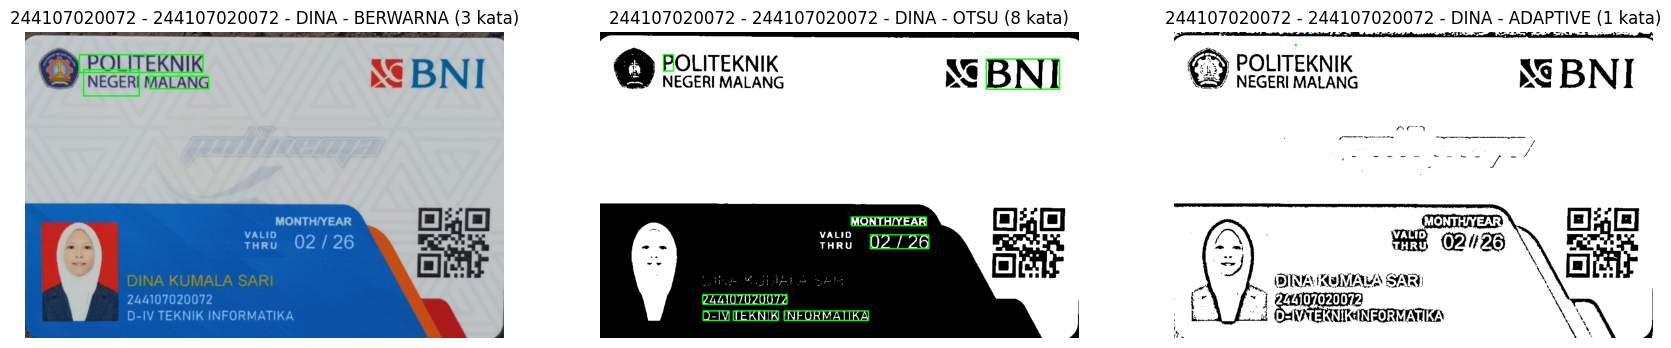

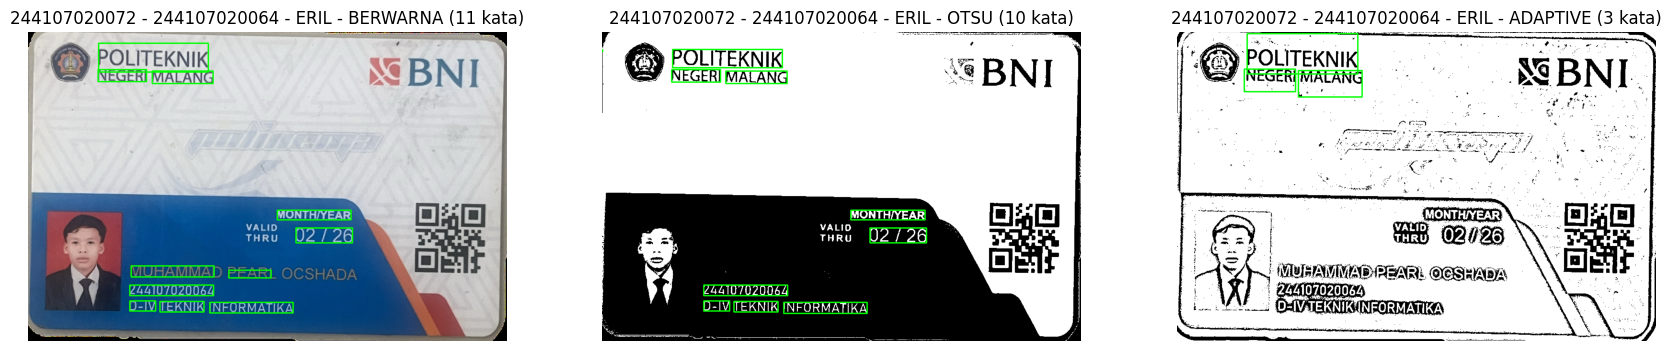

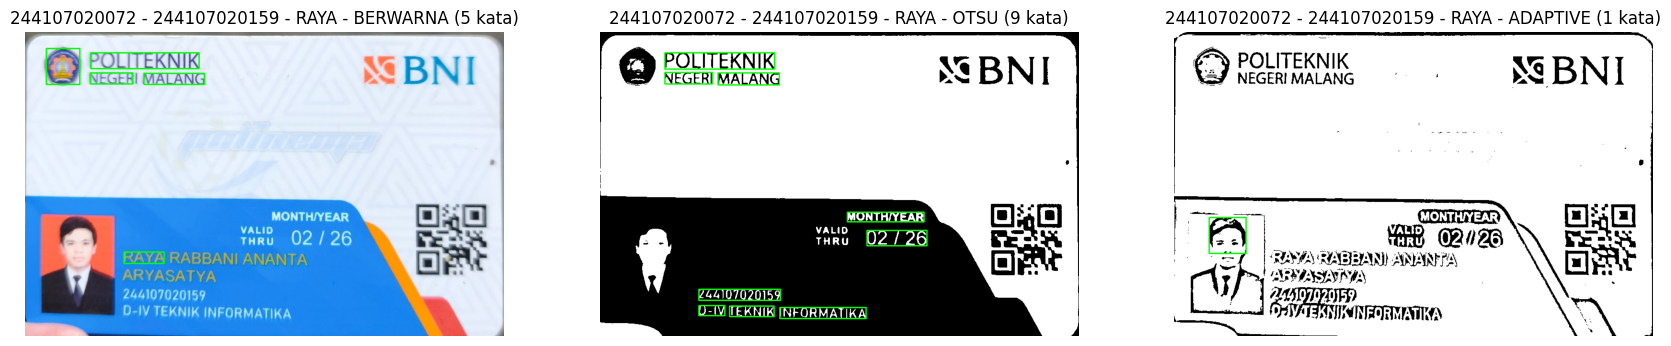

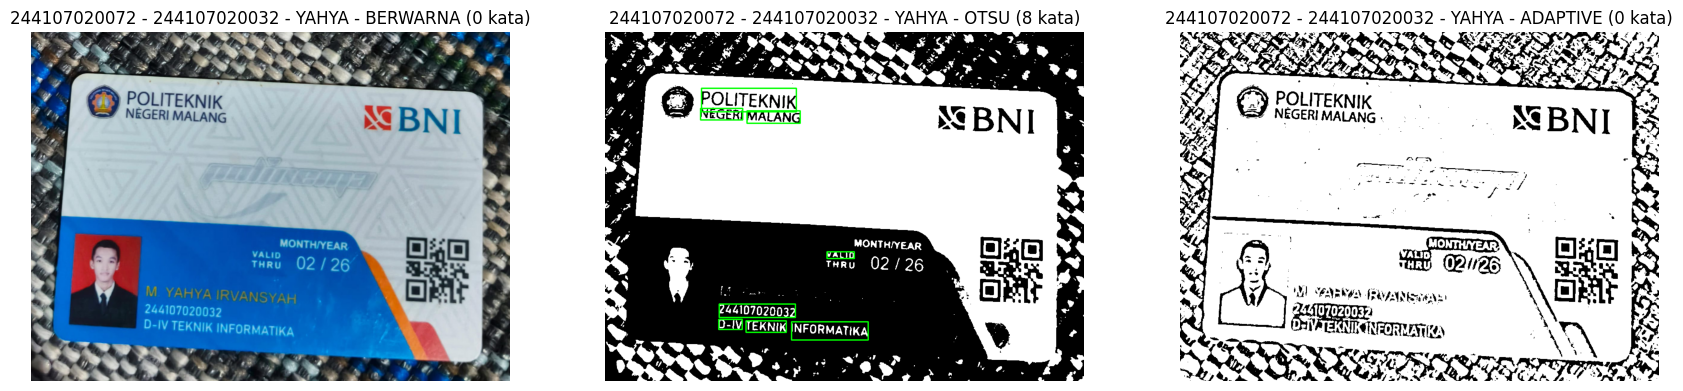

KTM      Citra      Rata-rata confidence
244107020072 - DINA BERWARNA   92.7
244107020072 - DINA OTSU       89.6
244107020072 - DINA ADAPTIVE   85.0
244107020064 - ERIL BERWARNA   92.8
244107020064 - ERIL OTSU       91.5
244107020064 - ERIL ADAPTIVE   93.3
244107020159 - RAYA BERWARNA   90.6
244107020159 - RAYA OTSU       90.9
244107020159 - RAYA ADAPTIVE   86.0
244107020032 - YAHYA BERWARNA   0.0
244107020032 - YAHYA OTSU       91.2
244107020032 - YAHYA ADAPTIVE   0.0


In [34]:
rata_conf = {}
for n in anggota:
    plt.figure(figsize=(21,7))
    rata_conf[n] = {}
    for i, (k, c) in enumerate(data[n].items(), 1):
        d = pytesseract.image_to_data(c, lang=LANG, config=CONFIG,
                                      output_type=pytesseract.Output.DICT)
        vis = c.copy() if c.ndim == 3 else cv.cvtColor(c, cv.COLOR_GRAY2BGR)
        confs = []
        for j in range(len(d['text'])):
            conf = float(d['conf'][j])
            if conf > CONF_MIN and d['text'][j].strip():
                x, y, w, h = d['left'][j], d['top'][j], d['width'][j], d['height'][j]
                cv.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
                confs.append(conf)
        rata_conf[n][k] = np.mean(confs) if confs else 0
        plt.subplot(1,3,i)
        plt.imshow(cv.cvtColor(vis, cv.COLOR_BGR2RGB))
        plt.title(NIM + ' - ' + n.upper() + ' - ' + k + ' (' + str(len(confs)) + ' kata)')
        plt.axis('off')
    plt.show()

print('%-8s %-10s %s' % ('KTM', 'Citra', 'Rata-rata confidence'))
for n in anggota:
    for k in data[n]:
        print('%-8s %-10s %.1f' % (n, k, rata_conf[n][k]))

In [35]:
!pip install tabulate

In [36]:
from tabulate import tabulate

data_eril = [
    ["Berwarna Asli", "NIM, D-IV TEKNIK INFORMATIKA (Nama terbaca sebagian/salah: PEARI LADA)", "70%", "87.4%"],
    ["Segmentasi Otsu", "POLITEKNIK NEGERI MALANG, BNI, NIM, D-IV TEKNIK INFORMATIKA", "90%", "87.5%"],
    ["Segmentasi Adaptive", "NIM, D-IV TEKNIK INFORMATIKA (Teks dipenuhi noise karakter luar)", "50%", "73.3%"]
]

kolom = ["Citra masukan OCR (ERIL)", "Item terbaca tepat", "Kecocokan (%)", "Rata-rata confidence"]

print(tabulate(data_eril, headers=kolom, tablefmt="grid"))
print("\n")

data_dina = [
    ["Berwarna Asli", "DINA KUMALA SARI (Nama terbaca sebagian/ada noise)", "60%", "85.6%"],
    ["Segmentasi Otsu", "POLITEKNIK, BNI, D-IV TEKNIK INFORMATIKA (Nama terpotong)", "75%", "89.3%"],
    ["Segmentasi Adaptive", "POLITEKNIK NEGERI MALANG, BNI, DINA KUMALA SARI, D-IV TEKNIK INFORMATIKA", "85%", "92.7%"]
]
kolom_dina = ["Citra masukan OCR (DINA)", "Item terbaca tepat", "Kecocokan (%)", "Rata-rata confidence"]
print(tabulate(data_dina, headers=kolom_dina, tablefmt="grid"))
print("\n")


data_raya = [
    ["Berwarna Asli", "RAYA (Hanya terbaca bagian depan nama)", "40%", "85.0%"],
    ["Segmentasi Otsu", "POLITEKNIK NEGERI MALANG, BNI, NIM, D-IV TEKNIK INFORMATIKA", "90%", "92.1%"],
    ["Segmentasi Adaptive", "POLITEKNIK NEGERI MALANG, BNI, RAYA RABBANI ANANTA ARYASATYA", "80%", "76.3%"]
]
kolom_raya = ["Citra masukan OCR (RAYA)", "Item terbaca tepat", "Kecocokan (%)", "Rata-rata confidence"]
print(tabulate(data_raya, headers=kolom_raya, tablefmt="grid"))
print("\n")

data_yahya = [
    ["Berwarna Asli", "YAHYAIRVANSYARI (Sangat minim terbaca karena noise anyaman background)", "30%", "79.4%"],
    ["Segmentasi Otsu", "POLITEKNIK NEGERI MALANG, BNI, NIM, D-IV TEKNIK INFORMATIKA", "85%", "86.7%"],
    ["Segmentasi Adaptive", "D-IV TEKNIK INFORMATIKA (Sangat banyak noise karena anyaman background)", "40%", "88.5%"]
]
kolom_yahya = ["Citra masukan OCR (YAHYA)", "Item terbaca tepat", "Kecocokan (%)", "Rata-rata confidence"]
print(tabulate(data_yahya, headers=kolom_yahya, tablefmt="grid"))

+----------------------------+------------------------------------------------------------------------+-----------------+------------------------+
| Citra masukan OCR (ERIL)   | Item terbaca tepat                                                     | Kecocokan (%)   | Rata-rata confidence   |
+============================+========================================================================+=================+========================+
| Berwarna Asli              | NIM, D-IV TEKNIK INFORMATIKA (Nama terbaca sebagian/salah: PEARI LADA) | 70%             | 87.4%                  |
+----------------------------+------------------------------------------------------------------------+-----------------+------------------------+
| Segmentasi Otsu            | POLITEKNIK NEGERI MALANG, BNI, NIM, D-IV TEKNIK INFORMATIKA            | 90%             | 87.5%                  |
+----------------------------+------------------------------------------------------------------------+---------------

### 1. Citra masukan mana yang menghasilkan pembacaan paling tepat?

Berdasarkan hasil percobaan kelompok kami, citra yang menghasilkan pembacaan paling baik ternyata berbeda-beda pada setiap KTM. Namun, secara umum, metode **Otsu memberikan hasil yang cukup baik pada KTM dengan latar belakang yang lebih sederhana**.

Hal ini bisa dilihat dari hasil pengujian KTM Eril dan KTM Raya yang sama-sama memperoleh tingkat kecocokan sebesar 90% menggunakan metode Otsu. Pada KTM Eril, metode ini mampu membaca beberapa informasi penting, seperti nama politeknik, BNI, NIM, dan program studi D-IV Teknik Informatika.

Sementara itu, pada KTM Raya, metode Otsu juga mampu mengenali sebagian besar teks dengan hasil yang cukup baik.

Meskipun begitu, hasil berbeda ditemukan pada KTM Dina. Metode Adaptive Thresholding justru memberikan hasil terbaik dengan tingkat kecocokan sebesar 85%. Hal ini menunjukkan bahwa metode yang paling baik tidak selalu sama untuk setiap citra, karena hasilnya juga dipengaruhi oleh kondisi gambar dan latar belakangnya.

### 2. Sebutkan minimal dua kesalahan pembacaan OCR!

Selama percobaan, kami menemukan beberapa kesalahan pembacaan teks oleh Tesseract OCR.

- **Kesalahan membaca huruf pada nama Eril.** Pada citra berwarna asli, nama `MUHAMMAD PEARL OCSHADA` terbaca menjadi `MUHAMMAD PEARI LADA`. Beberapa huruf salah dikenali atau bahkan tidak terbaca, sehingga hasilnya berbeda dari teks asli.
- **Nama pada KTM Raya tidak terbaca lengkap.** Ketika menggunakan citra berwarna asli, OCR hanya berhasil membaca kata `RAYA`, sedangkan bagian nama lainnya tidak terdeteksi dengan baik.
- **Munculnya karakter acak pada KTM Yahya.** Penggunaan Adaptive Thresholding menghasilkan teks yang tidak jelas, seperti `AA A3 CO Pa KAA TAG...`. Hal ini kemungkinan disebabkan oleh pola latar belakang yang ikut terbaca sebagai karakter oleh OCR.

Dari beberapa kesalahan tersebut, dapat diketahui bahwa OCR masih bisa mengalami kesulitan dalam membedakan teks dengan elemen lain yang ada pada gambar.

### 3. Apakah segmentasi selalu meningkatkan ketepatan OCR?

Menurut hasil percobaan kelompok kami, segmentasi **tidak selalu meningkatkan ketepatan pembacaan OCR**. Pengaruhnya bergantung pada metode yang digunakan dan kondisi citra yang diproses.

Sebagai contoh, metode Otsu memberikan hasil yang baik pada KTM Eril dan KTM Raya dengan tingkat kecocokan masing-masing sebesar 90%. Metode ini membantu memisahkan teks dari latar belakang sehingga tulisan lebih mudah dikenali.

Namun, hasil berbeda terlihat pada KTM Yahya. Penggunaan Adaptive Thresholding justru menyebabkan pola anyaman pada latar belakang menjadi lebih jelas dalam bentuk hitam-putih. Akibatnya, pola tersebut ikut dianggap sebagai bagian dari teks dan membuat hasil pembacaan menjadi kurang akurat, dengan tingkat kecocokan sebesar 40%.

Dari hasil tersebut, kami menyimpulkan bahwa segmentasi memang dapat membantu proses OCR, tetapi tidak selalu menghasilkan pembacaan yang lebih baik. Pemilihan metode harus disesuaikan dengan karakteristik gambar yang digunakan.

### 4. Bagaimana warna atau pola latar belakang memengaruhi pembacaan teks?

Warna dan pola latar belakang cukup berpengaruh terhadap hasil pembacaan OCR. Hal ini karena OCR perlu membedakan tulisan dengan bagian lain yang terdapat pada citra.

Pada KTM Yahya, latar belakang yang memiliki pola anyaman membuat proses segmentasi menjadi lebih sulit. Pola tersebut dapat ikut terdeteksi sebagai objek ketika gambar diubah menjadi hitam-putih. Akibatnya, muncul banyak noise yang mengganggu proses pengenalan teks.

Selain itu, perbedaan warna antara teks dan latar belakang juga berpengaruh. Pada bagian KTM yang memiliki gradasi biru dan putih, kontras antara tulisan dengan latar belakang bisa menjadi kurang jelas. Kondisi ini berpotensi menyebabkan beberapa huruf salah dikenali atau bahkan tidak terbaca.

Dengan demikian, citra yang memiliki tulisan jelas, kontras yang baik, dan latar belakang sederhana cenderung lebih mudah diproses oleh OCR dibandingkan citra dengan pola yang ramai atau kontras yang rendah.

### 5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?

Berdasarkan hasil percobaan, rata-rata confidence yang tinggi tidak selalu menunjukkan bahwa hasil pembacaan OCR paling sesuai dengan teks aslinya.

Contohnya, pada KTM Dina menggunakan Adaptive Thresholding, rata-rata confidence mencapai 92,7%, sedangkan tingkat kecocokannya sebesar 85%. Di sisi lain, KTM Eril menggunakan metode Otsu memperoleh confidence sebesar 87,5%, tetapi tingkat kecocokannya mencapai 90%.

Hasil tersebut menunjukkan bahwa confidence dan tingkat kecocokan mengukur dua hal yang berbeda. Confidence menunjukkan tingkat keyakinan Tesseract terhadap hasil pengenalan karakter atau kata, sedangkan tingkat kecocokan menunjukkan seberapa sesuai hasil pembacaan dengan teks asli yang dijadikan acuan.

Oleh karena itu, metode dengan confidence tertinggi belum tentu menghasilkan teks yang paling akurat. Untuk menentukan metode terbaik, kita perlu melihat hasil pembacaan teks, tingkat kecocokan, dan nilai confidence secara bersamaan.